In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [4]:
display(df.head())
display(df.shape)
display(df.info())
display(df.columns)
display(df.isna().sum())

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


(2443651, 9)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


None

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

## Part 1: Understanding Product Categories

**Business Question:**  
What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

### 1.Frequency Tables:

Generate a frequency table for the product category.

Which are the top 5 most listed product categories?

In [5]:
category_frequency = df["category"].value_counts()

category_frequency_df = (df["category"].value_counts().reset_index())

category_frequency_df.columns = ["category", "listing_count"]
top_5_categories = category_frequency_df.head(5)

top_5_categories

,category,listing_count
0,Sports & Outdoors,836265
1,Beauty,19312
2,"Handmade Clothing, Shoes & Accessories",19229
3,Bath & Body,19092
4,Birthday Gifts,18978


### 2. Visualizations:

Display the distribution of products across different categories using a bar chart. If you face problems understanding the chart, do it for a subset of top categories.
For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

C:\Users\johan\AppData\Local\Temp\ipykernel_32308\1091388367.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=top_categories_bar, x="listing_count", y="category", palette=earth_bar_colors)


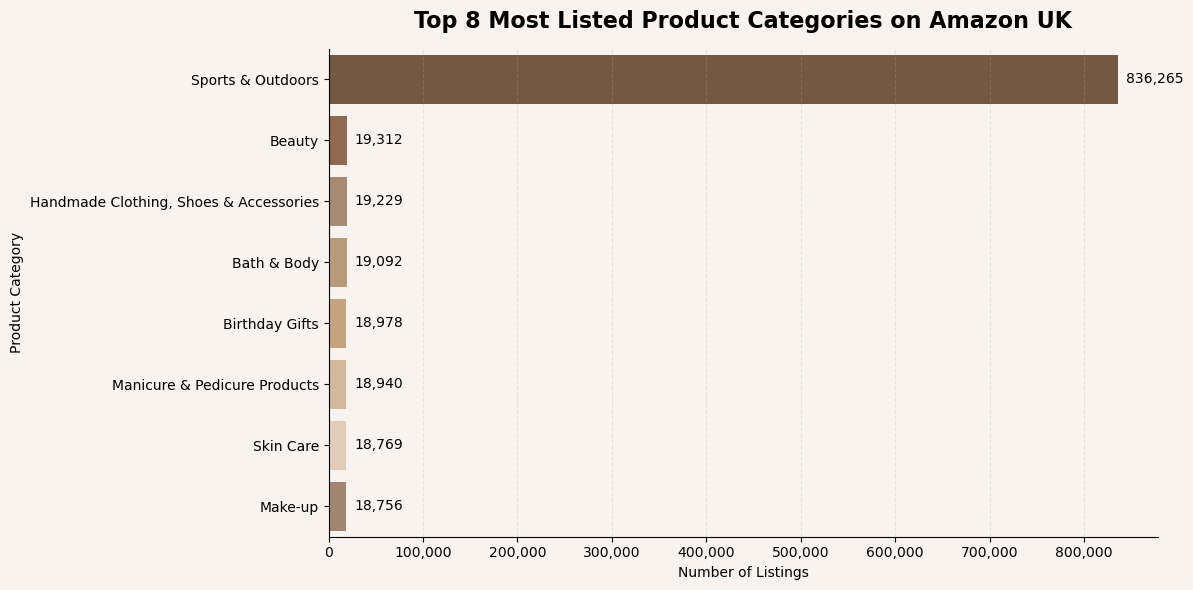

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

top_categories_bar = category_frequency_df.head(8).copy()

earth_bar_colors = ["#7F5539", "#9C6644", "#B08968", "#C49A6C", "#D4A373", "#DDB892", "#E6CCB2", "#A98467"]

plt.figure(figsize=(12, 6), facecolor="#F8F3EE")
ax = sns.barplot(data=top_categories_bar, x="listing_count", y="category", palette=earth_bar_colors)

ax.set_facecolor("#F8F3EE")

plt.title("Top 8 Most Listed Product Categories on Amazon UK", fontsize=16, weight="bold", pad=15)
plt.xlabel("Number of Listings")
plt.ylabel("Product Category")

ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{int(x):,}"))
plt.grid(axis="x", linestyle="--", alpha=0.25)

for i, value in enumerate(top_categories_bar["listing_count"]):
    ax.text(value + max(top_categories_bar["listing_count"]) * 0.01, i, f"{value:,}", va="center", fontsize=10)

sns.despine()
plt.tight_layout()
plt.show()

C:\Users\johan\AppData\Local\Temp\ipykernel_32308\3924218505.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=top_categories_no_first, x="listing_count", y="category", palette=earth_bar_colors_2)


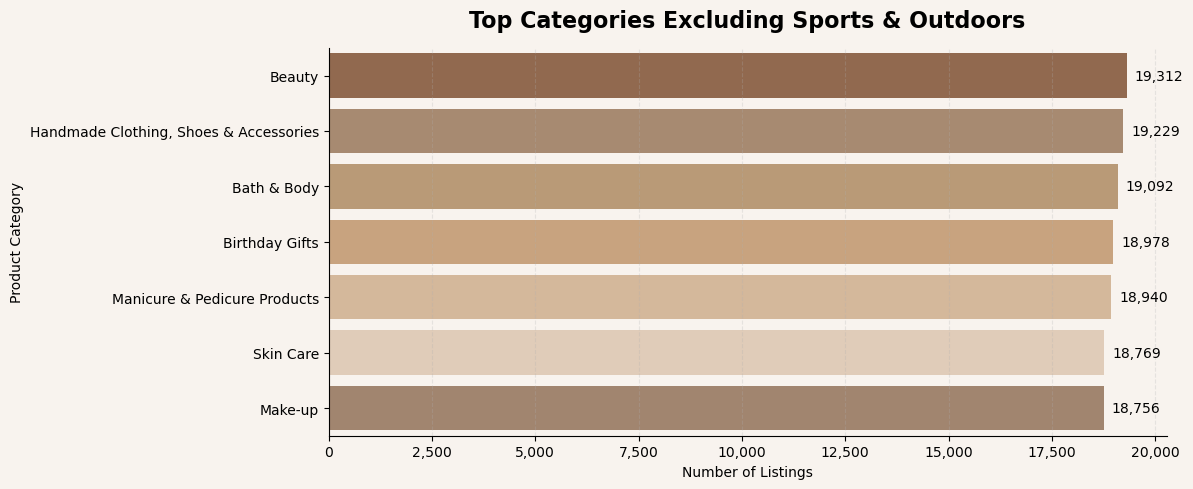

In [18]:
top_categories_no_first = category_frequency_df.iloc[1:8].copy()

earth_bar_colors_2 = ["#9C6644", "#B08968", "#C49A6C", "#D4A373", "#DDB892", "#E6CCB2", "#A98467"]

plt.figure(figsize=(12, 5), facecolor="#F8F3EE")
ax = sns.barplot(data=top_categories_no_first, x="listing_count", y="category", palette=earth_bar_colors_2)

ax.set_facecolor("#F8F3EE")

plt.title("Top Categories Excluding Sports & Outdoors", fontsize=16, weight="bold", pad=15)
plt.xlabel("Number of Listings")
plt.ylabel("Product Category")

ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{int(x):,}"))
plt.grid(axis="x", linestyle="--", alpha=0.25)

for i, value in enumerate(top_categories_no_first["listing_count"]):
    ax.text(value + max(top_categories_no_first["listing_count"]) * 0.01, i, f"{value:,}", va="center", fontsize=10)

sns.despine()
plt.tight_layout()
plt.show()

The bar chart shows that product listings are highly concentrated in a small number of categories. Sports & Outdoors is by far the most frequently listed category, clearly exceeding all others by a large margin.

Because this category dominates the dataset, a second comparison excluding it can help better visualize the differences among the remaining categories.

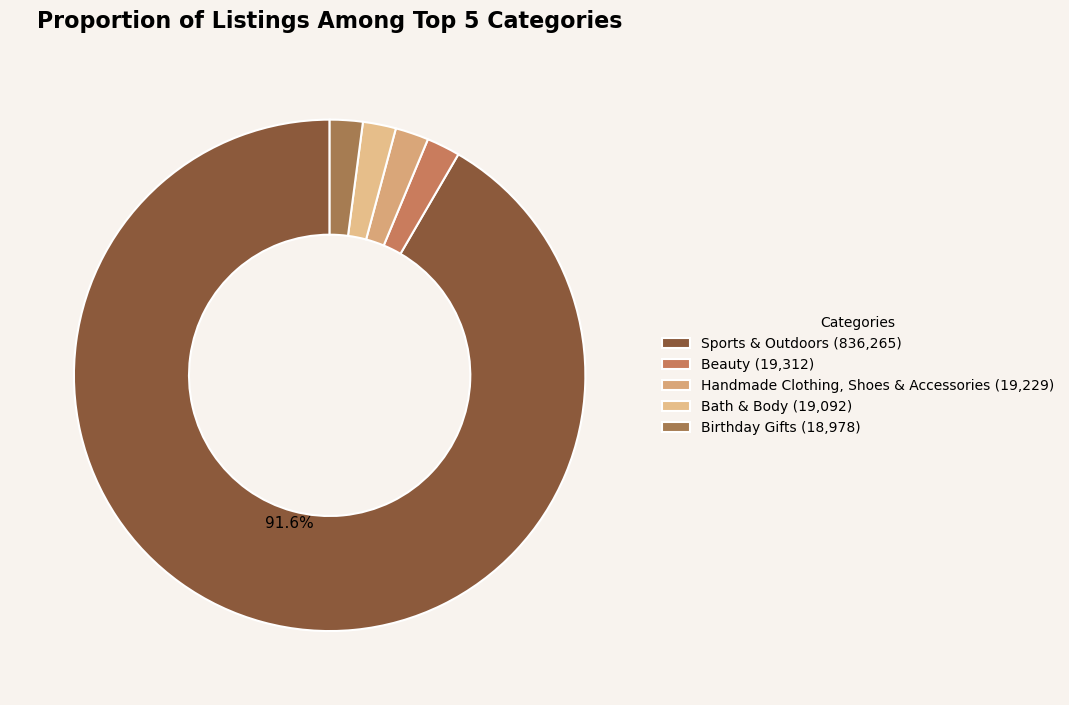

In [19]:
top_5_categories = category_frequency_df.head(5).copy()

earth_pie_colors = ["#8C5A3C", "#C97C5D", "#D9A679", "#E6BE8A", "#A67C52"]

def autopct_format(pct):
    return f"{pct:.1f}%" if pct >= 3 else ""

plt.figure(figsize=(10, 8), facecolor="#F8F3EE")

wedges, texts, autotexts = plt.pie(
    top_5_categories["listing_count"],
    labels=None,
    colors=earth_pie_colors,
    autopct=autopct_format,
    startangle=90,
    wedgeprops={"edgecolor": "white", "linewidth": 1.5, "width": 0.45},
    textprops={"fontsize": 11}
)

plt.title("Proportion of Listings Among Top 5 Categories", fontsize=16, weight="bold", pad=20)

plt.legend(
    wedges,
    [f"{cat} ({count:,})" for cat, count in zip(top_5_categories["category"], top_5_categories["listing_count"])],
    title="Categories",
    loc="center left",
    bbox_to_anchor=(1, 0.5),
    frameon=False
)

plt.tight_layout()
plt.show()

The pie chart confirms that Sports & Outdoors dominates the top product categories by a very large margin. The remaining categories represent only small shares of the total listings, indicating that the dataset is heavily concentrated rather than evenly distributed across categories.

## Part 2: Delving into Product Pricing
Business Question: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

### 1. Measures of Centrality:

Calculate the mean, median, and mode for the price of products.
What's the average price point of products listed? How does this compare with the most common price point (mode)?

In [25]:
price = df.loc[df["price"] > 0, "price"].dropna()
price_mean = price.mean()
price_median = price.median()
price_mode = price.mode().iloc[0]

centrality_summary = pd.DataFrame({"measure": ["Mean", "Median", "Mode"], "value": [price_mean, price_median, price_mode]})

centrality_summary

,measure,value
0,Mean,89.24454
1,Median,19.09000
2,Mode,9.99000


### 2. Measures of Dispersion:

Determine the variance, standard deviation, range, and interquartile range for product price.
How varied are the product prices? Are there any indicators of a significant spread in prices?

In [30]:
price_variance = price.var()
price_std = price.std()
price_range = price.max() - price.min()

q1 = price.quantile(0.25)
q3 = price.quantile(0.75)
price_iqr = q3 - q1

dispersion_summary = pd.DataFrame({"measure": ["Variance", "Standard Deviation", "Range", "Interquartile Range"], "value": [price_variance, price_std, price_range, price_iqr]})

dispersion_summary

,measure,value
0,Variance,119446.397743
1,Standard Deviation,345.610182
2,Range,99999.990000
3,Interquartile Range,36.000000


### 3. Visualizations:

Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. If its hard to read these diagrams, think why this is, and explain how it could be solved..
Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.

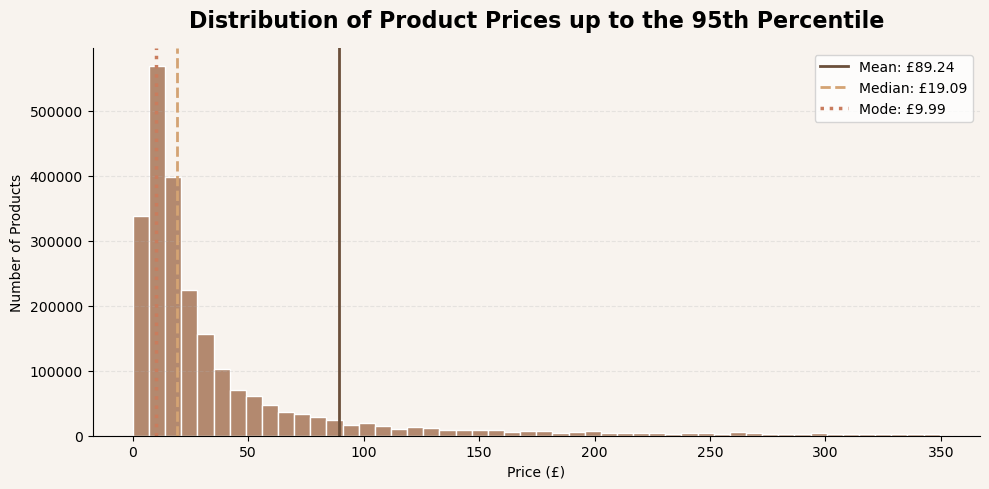

In [38]:
price_log = df.loc[df["price"] > 0, "price"].dropna()

price_mean = price_log.mean()
price_median = price_log.median()
price_mode = price_log.mode().iloc[0]

log_bins = np.logspace(np.log10(price_log.min()), np.log10(price_log.max()), 60)

price_95 = price.quantile(0.95)
price_filtered = price[price <= price_95]

plt.figure(figsize=(10, 5), facecolor="#F8F3EE")
ax = sns.histplot(price_filtered, bins=50, color="#9C6644", edgecolor="white")

ax.set_facecolor("#F8F3EE")

plt.axvline(price_mean, color="#6B4F3A", linestyle="-", linewidth=2, label=f"Mean: £{price_mean:.2f}")
plt.axvline(price_median, color="#D4A373", linestyle="--", linewidth=2, label=f"Median: £{price_median:.2f}")
plt.axvline(price_mode, color="#C97C5D", linestyle=":", linewidth=2.5, label=f"Mode: £{price_mode:.2f}")

plt.title("Distribution of Product Prices up to the 95th Percentile", fontsize=16, weight="bold", pad=15)
plt.xlabel("Price (£)")
plt.ylabel("Number of Products")

plt.grid(axis="y", linestyle="--", alpha=0.25)
plt.legend()
sns.despine()
plt.tight_layout()
plt.show()

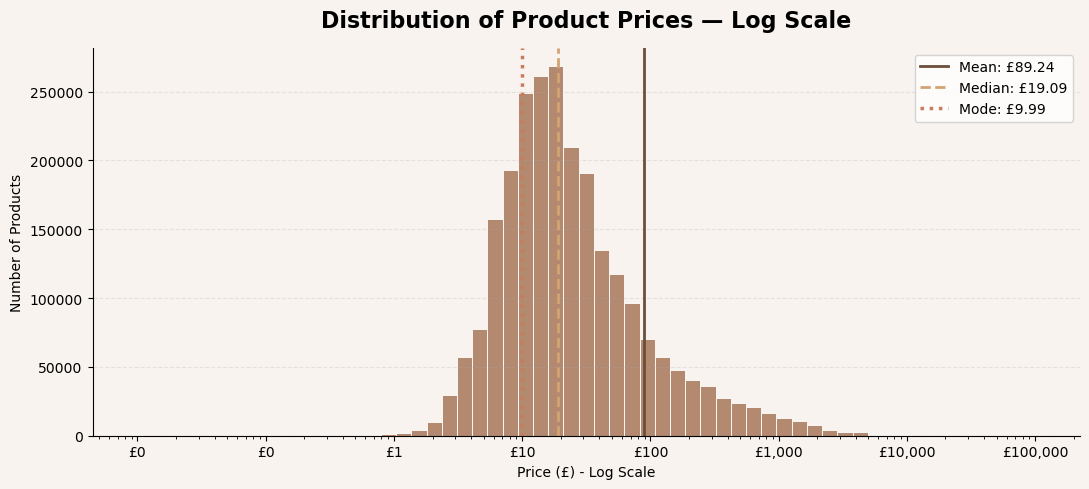

In [39]:
price_mean = price_log.mean()
price_median = price_log.median()
price_mode = price_log.mode().iloc[0]

plt.figure(figsize=(11, 5), facecolor="#F8F3EE")

ax = sns.histplot(price_log, bins=log_bins, color="#9C6644", edgecolor="white", linewidth=0.6)

ax.set_facecolor("#F8F3EE")
ax.set_xscale("log")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"£{x:,.0f}"))

plt.axvline(price_mean, color="#6B4F3A", linestyle="-", linewidth=2, label=f"Mean: £{price_mean:.2f}")
plt.axvline(price_median, color="#D4A373", linestyle="--", linewidth=2, label=f"Median: £{price_median:.2f}")
plt.axvline(price_mode, color="#C97C5D", linestyle=":", linewidth=2.5, label=f"Mode: £{price_mode:.2f}")

plt.title("Distribution of Product Prices — Log Scale", fontsize=16, weight="bold", pad=15)
plt.xlabel("Price (£) - Log Scale")
plt.ylabel("Number of Products")

plt.grid(axis="y", linestyle="--", alpha=0.25)
plt.legend()

sns.despine()
plt.tight_layout()
plt.show()

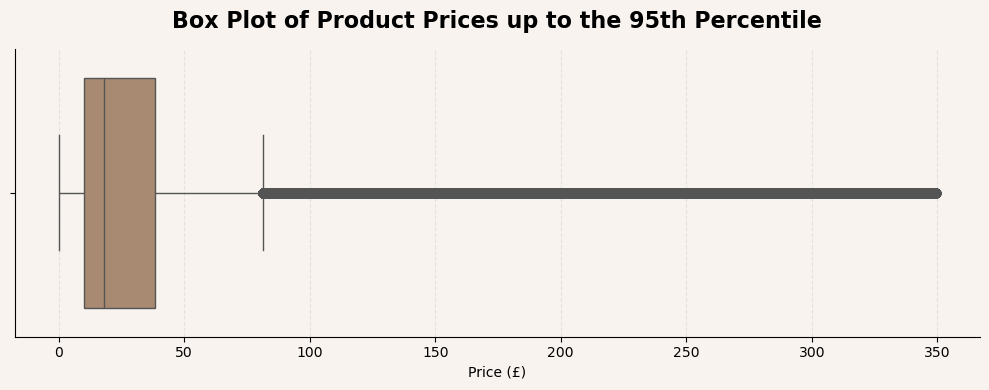

In [35]:
plt.figure(figsize=(10, 4), facecolor="#F8F3EE")
ax = sns.boxplot(x=price_filtered, color="#B08968")

ax.set_facecolor("#F8F3EE")

plt.title("Box Plot of Product Prices up to the 95th Percentile", fontsize=16, weight="bold", pad=15)
plt.xlabel("Price (£)")

plt.grid(axis="x", linestyle="--", alpha=0.25)
sns.despine()
plt.tight_layout()
plt.show()

In [36]:
lower_bound = q1 - 1.5 * price_iqr
upper_bound = q3 + 1.5 * price_iqr

price_outliers = df[df["price"] > upper_bound].copy()

print(f"Upper outlier threshold: £{upper_bound:.2f}")
print(f"Number of high-price outliers: {price_outliers.shape[0]}")
print(f"Percentage of products classified as high-price outliers: {(price_outliers.shape[0] / len(price) * 100):.2f}%")

Upper outlier threshold: £99.99
Number of high-price outliers: 327688
Percentage of products classified as high-price outliers: 13.41%


## Part 3: Unpacking Product Ratings
Business Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

### 1. Measures of Centrality:

Calculate the mean, median, and mode for the rating of products.
How do customers generally rate products? Is there a common trend?


In [43]:
df["stars"] = pd.to_numeric(df["stars"], errors="coerce")

ratings = df.loc[df["stars"] > 0, "stars"].dropna()

display(ratings.head())

zero_ratings_count = (df["stars"] == 0).sum()
zero_ratings_pct = zero_ratings_count / len(df) * 100

print(f"Products with 0 stars: {zero_ratings_count:,}")
print(f"Percentage of products with 0 stars: {zero_ratings_pct:.2f}%")

0    4.7
1    4.7
2    4.7
3    4.7
4    4.6
Name: stars, dtype: float64

Products with 0 stars: 1,225,641
Percentage of products with 0 stars: 50.16%


Products with 0 stars were excluded from the rating analysis because they most likely represent products without customer ratings rather than products genuinely rated as zero since that is not possible in amazon, so over 50% of products had no rating.

In [45]:
rating_mean = ratings.mean()
rating_median = ratings.median()
rating_mode = ratings.mode().iloc[0]

rating_centrality_summary = pd.DataFrame({
    "measure": ["Mean", "Median", "Mode"],
    "value": [rating_mean, rating_median, rating_mode]
})

rating_centrality_summary

,measure,value
0,Mean,4.319161
1,Median,4.400000
2,Mode,4.500000


### 2. Measures of Dispersion:

Determine the variance, standard deviation, and interquartile range for product rating.
Are the ratings consistent, or is there a wide variation in customer feedback?


In [46]:
rating_variance = ratings.var()
rating_std = ratings.std()

rating_q1 = ratings.quantile(0.25)
rating_q3 = ratings.quantile(0.75)
rating_iqr = rating_q3 - rating_q1

rating_dispersion_summary = pd.DataFrame({
    "measure": ["Variance", "Standard Deviation", "Interquartile Range"],
    "value": [rating_variance, rating_std, rating_iqr]
})

rating_dispersion_summary

,measure,value
0,Variance,0.308343
1,Standard Deviation,0.555287
2,Interquartile Range,0.500000



### 3. Shape of the Distribution:

Calculate the skewness and kurtosis for the rating column.
Are the ratings normally distributed, or do they lean towards higher or lower values?


In [49]:
rating_skewness = ratings.skew()
rating_kurtosis = ratings.kurtosis()

rating_shape_summary = pd.DataFrame({
    "measure": ["Skewness", "Kurtosis"],
    "value": [rating_skewness, rating_kurtosis]})
rating_shape_summary

,measure,value
0,Skewness,-2.379568
1,Kurtosis,9.781938


### 4. Visualizations:

Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

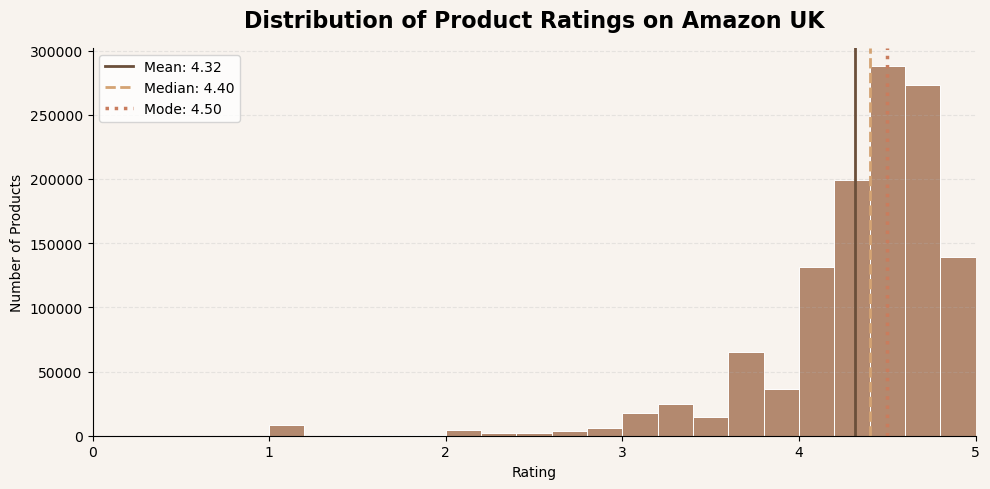

In [50]:
plt.figure(figsize=(10, 5), facecolor="#F8F3EE")

ax = sns.histplot(ratings, bins=20, color="#9C6644", edgecolor="white", linewidth=0.7)

ax.set_facecolor("#F8F3EE")

plt.axvline(rating_mean, color="#6B4F3A", linestyle="-", linewidth=2, label=f"Mean: {rating_mean:.2f}")
plt.axvline(rating_median, color="#D4A373", linestyle="--", linewidth=2, label=f"Median: {rating_median:.2f}")
plt.axvline(rating_mode, color="#C97C5D", linestyle=":", linewidth=2.5, label=f"Mode: {rating_mode:.2f}")

plt.title("Distribution of Product Ratings on Amazon UK", fontsize=16, weight="bold", pad=15)
plt.xlabel("Rating")
plt.ylabel("Number of Products")

plt.xlim(0, 5)
plt.grid(axis="y", linestyle="--", alpha=0.25)
plt.legend()

sns.despine()
plt.tight_layout()
plt.show()

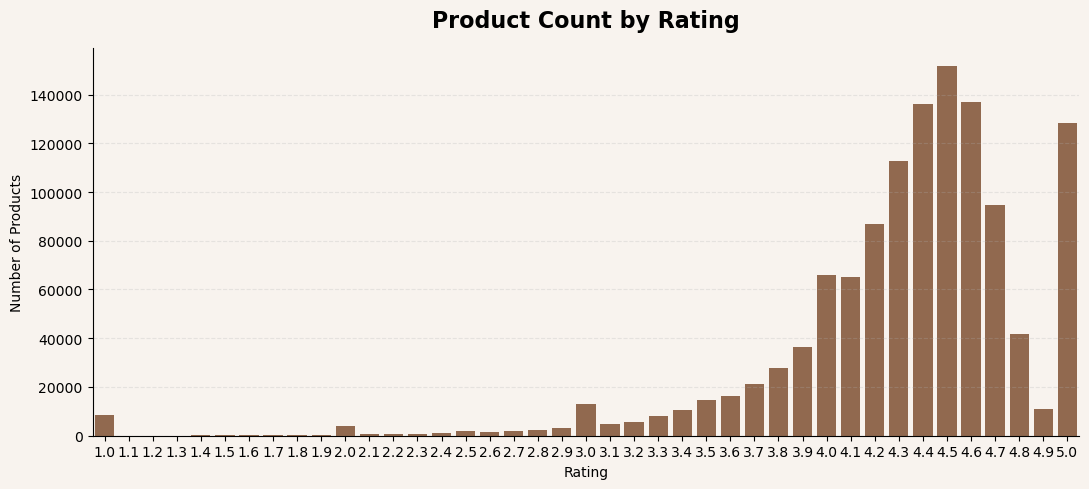

In [51]:
rating_distribution = ratings.round(1).value_counts().sort_index().reset_index()
rating_distribution.columns = ["rating", "product_count"]

plt.figure(figsize=(11, 5), facecolor="#F8F3EE")

ax = sns.barplot(data=rating_distribution, x="rating", y="product_count", color="#9C6644")

ax.set_facecolor("#F8F3EE")

plt.title("Product Count by Rating", fontsize=16, weight="bold", pad=15)
plt.xlabel("Rating")
plt.ylabel("Number of Products")

plt.grid(axis="y", linestyle="--", alpha=0.25)

sns.despine()
plt.tight_layout()
plt.show()